<a href="https://colab.research.google.com/github/pedroclealrocha/Fonte_inf_bd/blob/main/regressao_linear_estudantes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regressão linear: horas de estudo × nota da prova
Modelo no Google Colab com os mesmos dados usados no Excel (`student_exam_scores.csv`, 200 estudantes).

**Como usar:** Ambiente de execução → Executar tudo. Na célula 2, selecione o arquivo `student_exam_scores.csv` quando o Colab pedir.

## 1. Importar bibliotecas

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

## 2. Carregar os dados
Tenta baixar do GitHub; se falhar, pede o upload do arquivo.

In [2]:
url = "https://raw.githubusercontent.com/Sainathmudigonda/Student-Result-Analysis/main/student_exam_scores.csv"
try:
    df = pd.read_csv(url)
except Exception:
    from google.colab import files
    up = files.upload()
    df = pd.read_csv(list(up.keys())[0])
print(df.shape)
df.head()

(200, 6)


,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,8.0,8.8,72.1,45,30.2
1,S002,1.3,8.6,60.7,55,25.0
2,S003,4.0,8.2,73.7,86,35.8
3,S004,3.5,4.8,95.1,66,34.0
4,S005,9.1,6.4,89.8,71,40.3


In [3]:
df[['hours_studied', 'exam_score']].describe().round(2)

,hours_studied,exam_score
count,200.00,200.00
mean,6.33,33.96
std,3.23,6.79
min,1.00,17.10
25%,3.50,29.50
50%,6.15,34.05
75%,9.00,38.75
max,12.00,51.30


## 3. Gráfico de dispersão

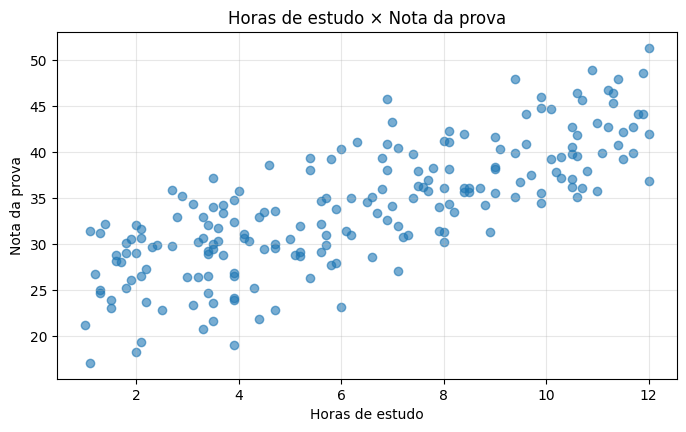

In [4]:
plt.figure(figsize=(8, 4.5))
plt.scatter(df.hours_studied, df.exam_score, alpha=.6)
plt.xlabel('Horas de estudo'); plt.ylabel('Nota da prova')
plt.title('Horas de estudo × Nota da prova'); plt.grid(alpha=.3)
plt.show()

## 4. Modelo de regressão linear

In [5]:
X = df[['hours_studied']]
y = df['exam_score']

modelo = LinearRegression().fit(X, y)
b0, b1 = modelo.intercept_, modelo.coef_[0]
r2 = r2_score(y, modelo.predict(X))
r = np.corrcoef(df.hours_studied, y)[0, 1]

print(f'Equação: nota = {b0:.4f} + {b1:.4f} × horas')
print(f'R² = {r2:.4f}   r = {r:.4f}')

Equação: nota = 23.6184 + 1.6341 × horas
R² = 0.6033   r = 0.7768


In [6]:
# statsmodels: traz também p-valor e intervalo de confiança
ols = sm.OLS(y, sm.add_constant(X)).fit()
print(ols.summary())
print('p-valor da inclinação:', ols.pvalues['hours_studied'])

                            OLS Regression Results                            
Dep. Variable:             exam_score   R-squared:                       0.603
Model:                            OLS   Adj. R-squared:                  0.601
Method:                 Least Squares   F-statistic:                     301.2
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           1.27e-41
Time:                        00:35:31   Log-Likelihood:                -573.90
No. Observations:                 200   AIC:                             1152.
Df Residuals:                     198   BIC:                             1158.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            23.6184      0.668     35.340

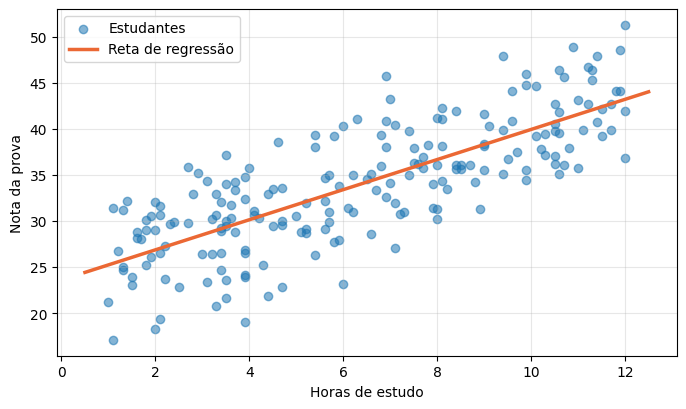

In [7]:
plt.figure(figsize=(8, 4.5))
plt.scatter(df.hours_studied, y, alpha=.55, label='Estudantes')
xs = np.linspace(0.5, 12.5, 100)
plt.plot(xs, b0 + b1 * xs, color='#eb6834', lw=2.5, label='Reta de regressão')
plt.xlabel('Horas de estudo'); plt.ylabel('Nota da prova')
plt.legend(); plt.grid(alpha=.3); plt.show()

## 5. Comparação com o modelo do Excel
Valores do Excel (arquivo `regressao_estudantes.xlsx`, aba `Regressão`: INCLINAÇÃO, INTERCEPÇÃO e RQUAD). Se refizer no seu Excel, substitua pelos valores que aparecem lá.

In [8]:
excel = {'Inclinação (b1)': 1.63410989612848,
         'Intercepto (b0)': 23.6184378520393,
         'R²': 0.603342791741874}
python = {'Inclinação (b1)': b1, 'Intercepto (b0)': b0, 'R²': r2}

comp = pd.DataFrame({'Excel': excel, 'Python (Colab)': python})
comp['Diferença absoluta'] = (comp['Excel'] - comp['Python (Colab)']).abs()
pd.options.display.float_format = '{:.10f}'.format
display(comp)
print('Iguais (tolerância 1e-9)?', bool(np.allclose(comp['Excel'], comp['Python (Colab)'], atol=1e-9)))

,Excel,Python (Colab),Diferença absoluta
Inclinação (b1),1.6341098961,1.6341098961,0.0000000000
Intercepto (b0),23.6184378520,23.6184378520,0.0000000000
R²,0.6033427917,0.6033427917,0.0000000000


Iguais (tolerância 1e-9)? True
